# E86: Does any other saved update's gain build gradually, and does the clean table work on it?

*2026-11-04, `qwen-decomp-lead`. Record: `reports/analyses/2026-11-04_analysis_e86-update-fractions.md`. Rules: `experiments/qwen_d1_fractions/results/predictions.json`.*

*For D1, a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement.*

**Status: provisional.**

**The answer.** Yes on the TOFU update: a tenth of it keeps about a quarter of the gain, and the share climbs as more is applied. The gold update builds partly, and the first fine-tune is saturated. The clean table passes least squares' in-span part and fails random and sign-flipped changes on all three, even on TOFU's far larger update. So "behaviour kept" has something to grade on TOFU, though it reads memory of trained rows there.


## What we were trying to test

D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. One column of its table is behaviour kept: how much of the update's loss drop a state's weights hold. On the first fine-tune a tenth of the update already keeps nearly all of it. So that column cannot grade anything there, since a placement could lose most of the update and still read as keeping the behaviour.

We read two other saved updates, to see whether either gains gradually, and whether the clean table still works on them.

**The updates, and why each is here.**

- **First fine-tune**, 10 steps on maths problems, the control. Its numbers exist from earlier runs, so any gap here is a bug.
- **Gold fine-tune**, 100 steps on maths problems. Its table already exists from an earlier run, so re-reading it is a second control, and only its fractions and share left in Δ are new.
- **TOFU fine-tune**, 1250 steps on 4000 rows of facts about invented authors. It is new here, and its update is about ten times the first fine-tune's by size.

**Fractions.** W0 is Qwen3-1.7B before the update, and δW the update. We add a share $t$ of δW to W0, with no masks, at $t$ of 0.1, 0.25, 0.5 and 1. Behaviour kept is the loss drop at that $t$ over the whole update's loss drop. It reads 0 at W0 and 1 at the updated model, and do-nothing reads 1 by construction, since its weights are the updated model's. On first and gold the rows are 256 held-out maths problems. On TOFU they are the 800 of the 4000 trained rows that have paraphrases, in their trained wording.

**The clean table.** $K$ is the forward KL from the updated model to a state, KL[updated ‖ state], with no masks, over every position. The ruler is $K$ at W0. A state at 0 of the ruler is the updated model, and a state at 1 is as far as W0 is. Do-nothing reads 0 by construction. The states are:

- **In-span part**: what the least-squares split's subcomponent change can express, with the remainder discarded.
- **Often-on half and rarely-on half**: the split over only that half of alive subcomponents, remainder discarded.
- **Adjoint split**: its change alone, remainder discarded.
- **Remainder**: W0 plus only what least squares cannot express.
- **Random change and sign-flipped change**: wrong changes at δW's size per matrix. These are what the table should fail.

**Share left in Δ.** The plain share of δW's squared size outside the subcomponents for least squares.

No masks and no Γ are used anywhere here, so nothing in this run is a faithfulness check.


## What we expected, and why

We filed "saturated" as a tenth of the update keeping 0.9 or more, and "builds" otherwise. Beside that label, "graded" is 0.5 or under and "partly" lies between. TOFU was a weak lean to build, since three quarters of its training loss drop comes after step 500, but a step is not a share of the update. Gold had no lean.

The table "works" when the in-span part is under 0.02 of the ruler and both wrong changes sit above the remainder by more than a row bootstrap's half-width. We leaned at medium that it works on TOFU, with its second-order term the least sure part. Least squares' share left in Δ was expected near 0.09, with no rule.


## What we observed

The first fine-tune reproduced every stored number, and gold's table reproduced with a gap of 0. TOFU has no reference, and its checks held.

### Does the gain build along the update?


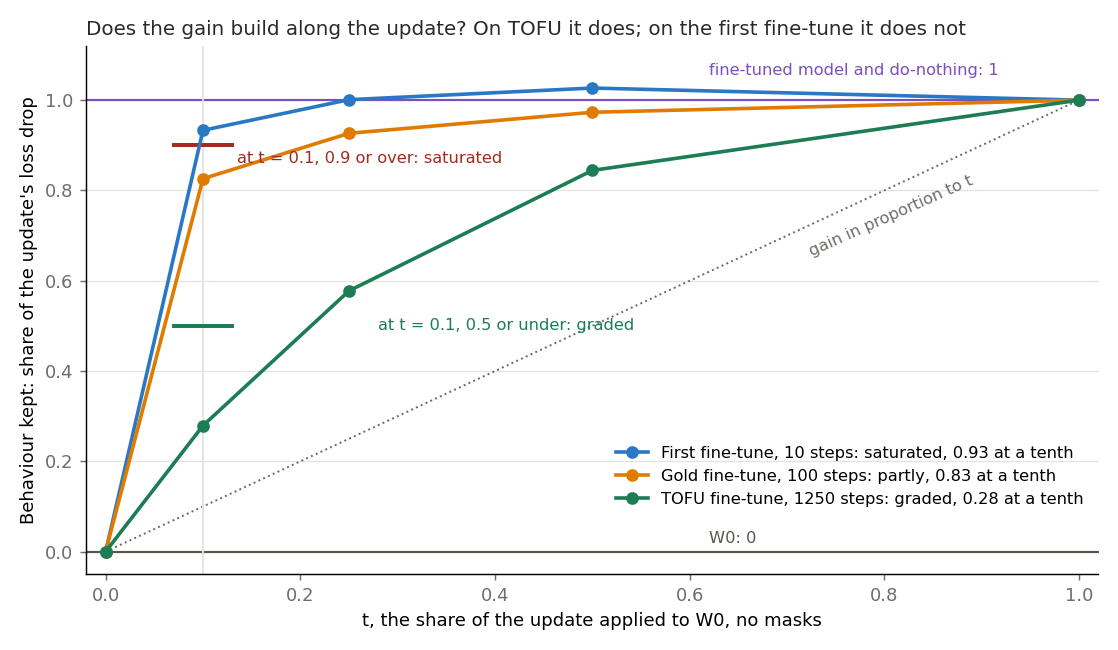

| update | kept at 0.1 | kept at 0.25 | kept at 0.5 | label |
|---|---|---|---|---|
| first fine-tune | 0.933 | 1.001 | 1.027 | saturated, saturated |
| gold fine-tune | 0.826 | 0.926 | 0.973 | builds, partly |
| TOFU fine-tune | 0.279 | 0.578 | 0.844 | builds, graded |

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_d1_fractions")
RES, FIG = ROOT / "results", ROOT / "figures"
NAMES = {"u1": "first fine-tune", "u2": "gold fine-tune", "tofu": "TOFU fine-tune"}
S = {u: json.loads((RES / f"score_{u}.json").read_text()) for u in NAMES}

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

show("kept_vs_t.png")
table(["update", "kept at 0.1", "kept at 0.25", "kept at 0.5", "label"],
      [[n] + [f"{S[u]['saturation']['kept'][t]:.3f}" for t in ("0.1", "0.25", "0.5")] + [S[u]["saturation"]["label"] + ", " + S[u]["saturation"]["band"]] for u, n in NAMES.items()])


**Reading it.** Yes on TOFU, partly on gold, and no on the first fine-tune. A tenth of the TOFU update keeps 0.28 of the gain, a quarter keeps 0.58 and a half keeps 0.84, above the dotted line a proportional gain would follow. Gold reads 0.83, then 0.93 and 0.97, so it carries the label "builds", though a tenth still holds most of its gain. The first fine-tune reads 0.93, 1.00 and 1.03, reproducing the earlier run. Its loss at half the update is below the whole update's, which the rule flags as a dip and does not act on. The caveat is TOFU's rows: they were trained, so this share reads memory, not generalisation.


### Does the clean table pass good splits and fail wrong changes?


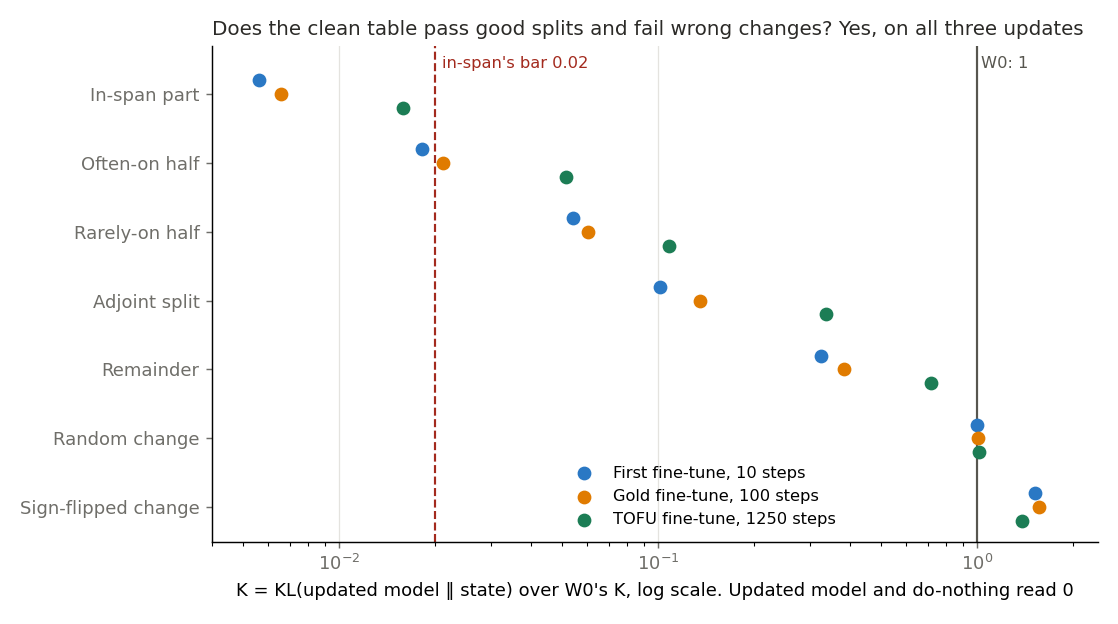

| K over the ruler | first fine-tune | gold fine-tune | TOFU fine-tune |
|---|---|---|---|
| in-span part | 0.006 | 0.007 | 0.016 |
| often-on half | 0.018 | 0.021 | 0.051 |
| rarely-on half | 0.054 | 0.060 | 0.108 |
| adjoint split | 0.101 | 0.135 | 0.336 |
| remainder | 0.325 | 0.383 | 0.717 |
| random change | 1.002 | 1.004 | 1.015 |
| sign-flipped change | 1.520 | 1.565 | 1.379 |
| verdict | works | works | works |

In [2]:
show("clean_table.png")
ROWS = (("inspan", "in-span part"), ("upper", "often-on half"), ("lower", "rarely-on half"), ("adjoint", "adjoint split"), ("remainder", "remainder"), ("random", "random change"), ("signs", "sign-flipped change"))
table(["K over the ruler"] + list(NAMES.values()),
      [[n] + [f"{S[u]['table']['over_ruler'][k]:.3f}" for u in NAMES] for k, n in ROWS]
      + [["verdict"] + [S[u]["table"]["verdict"] for u in NAMES]])


**Reading it.** Yes, it works on all three by the filed rule. The in-span part reads 0.006, 0.007 and 0.016 of the ruler, under the bar of 0.02. The random change reads about 1 on each, and the sign-flipped change 1.38 to 1.56, and both sit clearly above the remainder. TOFU reads higher in every good row, and its remainder is 0.72 of the ruler, so that update's margin is narrower. The table does not fail everything wrong. The rarely-on halves read 0.05 to 0.11, with no bar on them, and those states move the wrong columns towards the update. So this table has a rule that fails wrong directions, and none that fails wrong columns.


### Does least squares leave more in Δ on a larger update?


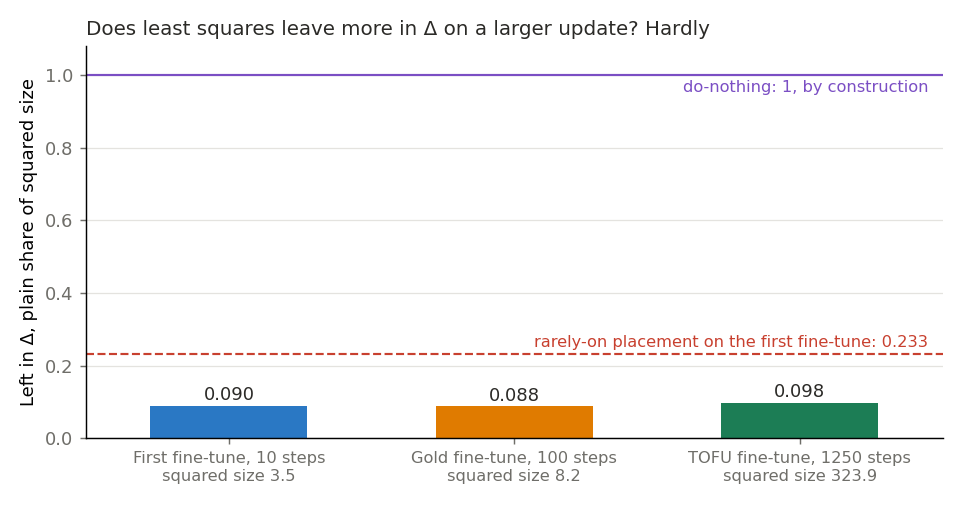

In [3]:
show("left_in_delta.png")


**Reading it.** Hardly. Least squares leaves 0.090, 0.088 and 0.098 in Δ, while the update's squared size grows about ninety-fold from the first fine-tune to TOFU. Do-nothing's 1 is by construction, and the rarely-on placement from the adversary run left 0.233 on the first fine-tune. This is plain squared size, so it says nothing about inputs. It also counts only what least squares leaves, since the adjoint's share reads near 0 whatever it loses, and the table's adjoint row reads that loss instead.


## What we learned

On Qwen3-1.7B there is now one update whose gain builds along it, the TOFU fine-tune. On that update, least squares still leaves about a tenth in Δ. Its in-span part stays under the bar, at about three times the first fine-tune's reading. The clean table fails wrong directions on all three updates, and no rule in it fails wrong columns. For `GOALS.md`'s weak version, this gives a larger real update to read placements on. It says nothing about whether the decomposition stays faithful there, since no masks were read.

**What this bears on, without deciding it.** The user has a pending question on what should judge D1, the map on Qwen3-1.7B that keeps the decomposition faithful for a real update, with three options:

- **A, the clean table, share left in Δ, size and kept on TOFU, with least squares as first map.** The table, share left in Δ and the update's kept share were all read on TOFU. No state had its kept share or squared size read there.
- **B, teacher training with masks in its loss as the map.** No teacher-trained state was read, and this names TOFU as an update it could be aimed at.
- **C, that aim cannot be met as worded.** That no rule in the table fails wrong columns is the case C turns on.

## How compelling is the evidence

Strong for the first fine-tune and gold, as controls, and moderate for TOFU, which is one update with one gain and no reference. The label comes from one gain per update, the loss.

- **Controls.** The first fine-tune's kept shares match the earlier run within 3e-8, and the table reads on the first and gold fine-tunes have a gap of 0.
- **Blind to.** The kept share reads one direction, the update's own, and on TOFU it reads trained rows. The table has no masks and no Γ, so it is not a faithfulness check. Each wrong change has one seed.
- **Noise.** W0's $K$ read twice agreed exactly, so the floor is 0. The bootstrap half-widths on the wrong changes are 0.03 to 0.17 nats.

## Surprises

No filed prediction reversed. Gold had no lean, and a tenth of it keeps 0.83, under the saturated bar by 0.07. The first fine-tune's dip at half the update is flagged, and no cause is claimed.

## What next

- **The user's question on what judges the map.** If A is taken, TOFU's kept share is a column with something to grade.
- **A kept share for any placement on TOFU.** If least squares' state reads near 1 and the adjoint's lower, the column separates them, as it could not on the first fine-tune.
- **Masks or the adversary on TOFU.** The first adversary read of this update, if the user keeps that test. If a bad placement fails here, the adversary's silence on the first fine-tune is specific to that update.

## Scorecard


In [4]:
sat = {u: S[u]["saturation"] for u in NAMES}
table(["id", "claim", "rule", "read", "verdict"], [
    ["u1 saturated", "first fine-tune saturates, as read before", "kept at 0.1 ≥ 0.9", f"{sat['u1']['kept']['0.1']:.3f}", sat["u1"]["label"]],
    ["u2", "gold, no lean", "same", f"{sat['u2']['kept']['0.1']:.3f}", sat["u2"]["label"] + ", " + sat["u2"]["band"]],
    ["tofu", "TOFU builds, weak lean", "same", f"{sat['tofu']['kept']['0.1']:.3f}", sat["tofu"]["label"] + ", " + sat["tofu"]["band"] + "; lean held"],
    ["table u1", "table works", "in-span under 0.02, wrong changes fail", f"{S['u1']['table']['over_ruler']['inspan']:.4f}", S["u1"]["table"]["verdict"]],
    ["table u2", "table works, E75's", "same", f"{S['u2']['table']['over_ruler']['inspan']:.4f}", S["u2"]["table"]["verdict"]],
    ["table tofu", "table works, medium lean", "same", f"{S['tofu']['table']['over_ruler']['inspan']:.4f}", S["tofu"]["table"]["verdict"] + "; lean held"],
    ["left u1", "least squares 0.0900, control", "within 1%", f"{S['u1']['left_in_delta']['ls']:.4f}", "held"],
    ["left others", "near 0.09, no rule", "reported", f"{S['u2']['left_in_delta']['ls']:.4f}, {S['tofu']['left_in_delta']['ls']:.4f}", "as read"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| u1 saturated | first fine-tune saturates, as read before | kept at 0.1 ≥ 0.9 | 0.933 | saturated |
| u2 | gold, no lean | same | 0.826 | builds, partly |
| tofu | TOFU builds, weak lean | same | 0.279 | builds, graded; lean held |
| table u1 | table works | in-span under 0.02, wrong changes fail | 0.0056 | works |
| table u2 | table works, E75's | same | 0.0066 | works |
| table tofu | table works, medium lean | same | 0.0159 | works; lean held |
| left u1 | least squares 0.0900, control | within 1% | 0.0900 | held |
| left others | near 0.09, no rule | reported | 0.0882, 0.0984 | as read |

## Departures from the literature

- **TOFU.** The dataset comes from Maini et al. 2024, which scores recall and forgetting with its own metrics. We read a response-token loss on 800 of the 4000 trained rows, to see how the gain builds, and no TOFU metric.
- **The fractions, the table, the ruler and the kept share.** These are this project's reads, with no published source. The least-squares split and the adjoint split are this project's too.
- **The adjoint's scale** is taken on maths rows on every update, as an earlier run did, so it is off TOFU's task.
- **Gold's file** is bf16, since no fp32 copy exists, and $t$ is multiplied in bf16. On the first fine-tune that changes the loss at a tenth by 2.5e-6 nats.

## Not run

1. A kept share for any placement or split on TOFU or gold.
2. A second gain, recall or accuracy, on any update.
3. Generalisation on TOFU: the rows read were trained.
4. Masks, Γ or the adversary on TOFU or gold, so no faithfulness read and nothing on what Γ reading V rounded to bf16 does.
5. Teacher training on TOFU.
6. More seeds of the wrong changes.

## Provenance

Results `experiments/qwen_d1_fractions/results/`: `score_u1.json`, `score_u2.json`, `score_tofu.json`, per-update reads, `run.log`. Figures from `plot.py`. Cluster L40, `debug` QoS, $0; jobs in the report. Not independently checked.
